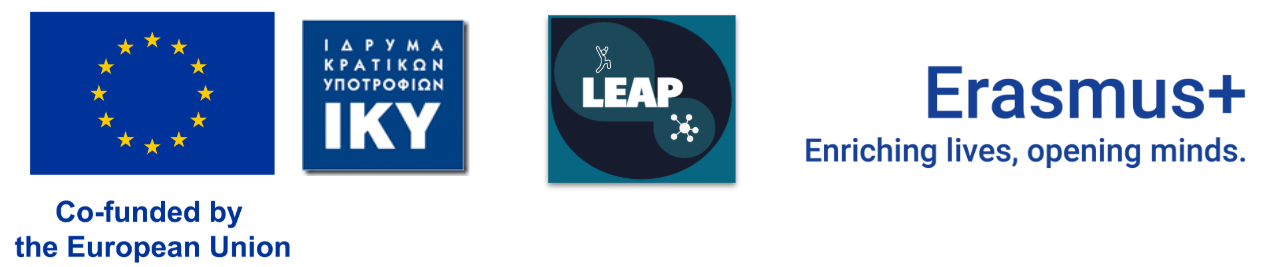

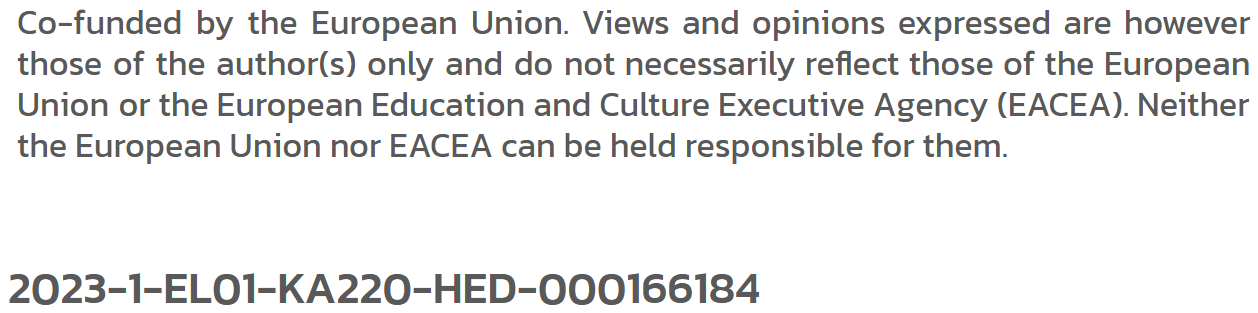

# Final Project, Option 1: Where does your CNN make its mistakes?

Software that reads handwritten numbers, such as postcodes on envelopes or account numbers on paper forms, must be judged not only on how often it is right but on where it goes wrong, because a confident misreading carries a real cost. In this project you build such a model and study the mistakes it makes.

In this project you build a convolutional neural network that recognises handwritten digits, then you study the mistakes it makes.

**Central question:** where does your CNN make its mistakes, and does one change to the model move them?

The data set is MNIST: 70,000 images of handwritten digits, each 28 by 28 pixels in greyscale, labelled 0 to 9. You download it yourself in the next cell.

This project draws on two earlier modules. In Module 5, we built and trained dense neural networks in Keras. In Module 6, we added convolutional layers, used Dropout and EarlyStopping to control overfitting, and read a confusion matrix to see which classes a model mixes up. Here you bring those skills together on a larger, more varied data set.

**How this notebook is organised.** The cells in Part A are already written for you. They handle the import, the download, and the reshaping that turns each flat row of 784 numbers back into a 28 by 28 image. From Part B onward, the cells are yours to complete. Each one carries comments describing what to do, along with a few hints, but not the finished code. Work through them in order.

Training on the full data set may take a few minutes per epoch on a laptop without a graphics card. This is expected.

## Part A. Setup and data

We start with the imports. This cell loads everything the notebook needs, so we run it once at the top.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import keras
from keras import layers

### Loading the data

We download MNIST from OpenML. The call returns the images in `X` as 70,000 rows of 784 numbers, and the labels in `y` as text. We convert the labels to integers so the model can work with them. The download runs once and may take a moment.

In [ ]:
X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True)
y = y.astype(int)

print("Images:", X.shape)
print("Labels:", y.shape, "| classes:", np.unique(y))

Images: (70000, 784)
Labels: (70000,) | classes: [0 1 2 3 4 5 6 7 8 9]


### Preparing the images

Each row of `X` is one image flattened into a line of 784 numbers. We reshape every row back into a 28 by 28 image with a single greyscale channel, and we scale the pixel values from the range 0 to 255 down to the range 0 to 1, which helps the network train. We then split the data into a training set and a test set, keeping the class balance with `stratify`, as we did in Module 3.

In [ ]:
X = X.reshape(-1, 28, 28, 1).astype("float32") / 255.0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training images:", X_train.shape)
print("Test images:    ", X_test.shape)

Training images: (56000, 28, 28, 1)
Test images:     (14000, 28, 28, 1)


### A first look at the images

Before modelling, we look at a few training images with their labels, to confirm the data loaded correctly.

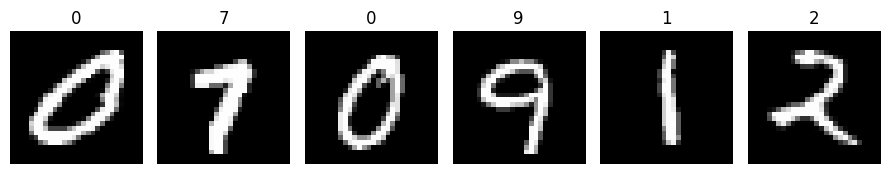

In [ ]:
fig, axes = plt.subplots(1, 6, figsize=(9, 2))
for ax, image, label in zip(axes, X_train, y_train):
    ax.imshow(image.reshape(28, 28), cmap="gray")
    ax.set_title(str(label))
    ax.axis("off")
plt.tight_layout()
plt.savefig("sample_digits.png", dpi=150, bbox_inches="tight")
plt.show()

## Part B. Build and train your network

From here on, the cells are yours to complete.

First, build a convolutional neural network with the Keras Sequential API, the same style you used in Module 6. Recall the shape of one image: 28 by 28, with one channel.

In [ ]:
keras.utils.set_random_seed(42)

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32,(3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

### Compile the model

Compiling sets the optimiser, the loss function, and the metric to watch during training.

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Train the model

Train the network, watching how it performs on data it has not learnt from. `EarlyStopping` halts training once the validation loss stops improving, so you do not waste time or overfit.

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop]
)

Epoch 1/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.9101 - loss: 0.3194 - val_accuracy: 0.9630 - val_loss: 0.1258
Epoch 2/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9680 - loss: 0.1096 - val_accuracy: 0.9759 - val_loss: 0.0828
Epoch 3/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9761 - loss: 0.0799 - val_accuracy: 0.9791 - val_loss: 0.0663
Epoch 4/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9796 - loss: 0.0653 - val_accuracy: 0.9793 - val_loss: 0.0589
Epoch 5/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9825 - loss: 0.0557 - val_accuracy: 0.9812 - val_loss: 0.0575
Epoch 6/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9856 - loss: 0.0470 - val_accuracy: 0.9864 - val_loss: 0.0494
Epoch 7/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9873 - loss: 0.0406 - val_accuracy: 0.9859 - val_loss: 0.0478
Epoch 8/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9888 - loss: 0.0364 - val_accuracy: 

### Learning curves

Plot the training and validation loss across the epochs. A validation curve that flattens or turns upward while the training curve keeps falling is a sign of overfitting.

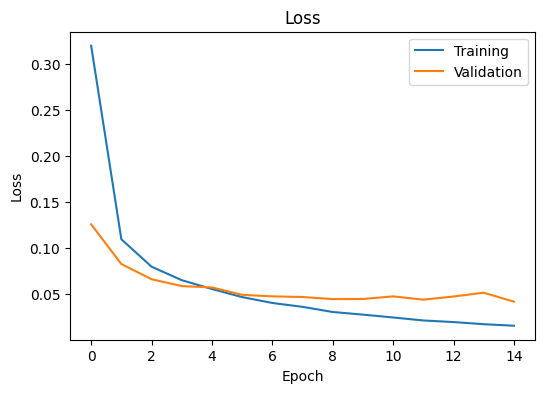

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()
plt.savefig("learning_curves_model1.png", dpi=150, bbox_inches="tight")
plt.show()

## Part C. Read the mistakes

Now measure how well the model does on the test set, the images it has never seen. This gives a reliable estimate of how it will perform on new images.

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test loss: {test_loss:.3f}")

y_pred_proba = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)


Test accuracy: 0.988
Test loss: 0.044


### The confusion matrix

The confusion matrix is where you answer the first half of the central question: where the mistakes are. Read it by rows. Each row is a true digit, each column is the digit the model predicted. The diagonal holds the correct predictions; every off-diagonal cell is a mistake, and its position tells you which digit was mistaken for which.

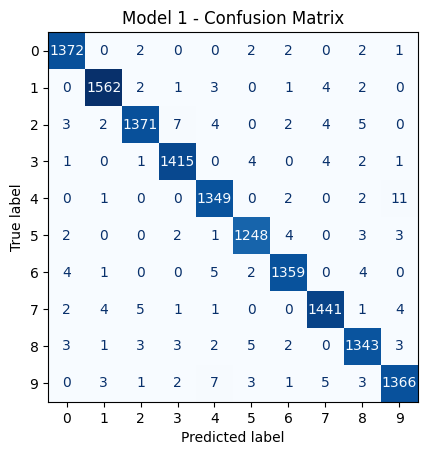

In [ ]:
cm1 = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm1, display_labels=range(10))
disp.plot(cmap="Blues", colorbar=False)
plt.title("Model 1 - Confusion Matrix")
plt.savefig("confusion_matrix_model1.png",dpi=150, bbox_inches="tight")
plt.show()

Some extra useful information from confusion matrix

In [ ]:
errors = cm1.copy()
np.fill_diagonal(errors, 0)
top = np.argsort(errors, axis=None)[::-1][:5]
for idx in top:
    true_d, pred_d = np.unravel_index(idx, errors.shape)
    print(f"True {true_d} → predicted {pred_d}: {errors[true_d, pred_d]} images")

True 4 → predicted 9: 11 images
True 9 → predicted 4: 7 images
True 2 → predicted 3: 7 images
True 9 → predicted 7: 5 images
True 7 → predicted 2: 5 images


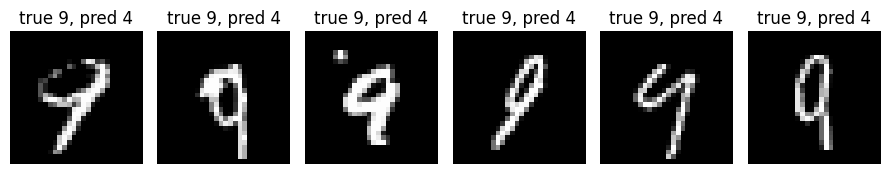

In [ ]:
wrong = np.where((y_test == 9) & (y_pred == 4))[0][:6]
fig, axes = plt.subplots(1, len(wrong), figsize=(9, 2))
for ax, i in zip(axes, wrong):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"true {y_test[i]}, pred {y_pred[i]}")
    ax.axis("off")
plt.tight_layout()
plt.savefig("misclassified_9_as_4.png", dpi=150, bbox_inches="tight")
plt.show()

### What did you find?

Look at the off-diagonal cells with the largest counts. Which pairs of digits does your model confuse most often? Some pairs are visually similar and are commonly mixed up.

**Write two or three sentences here** naming the two most common confusion pairs, recording the count for each one, and suggesting why those particular digits might be hard to tell apart. For example, if row 4 and column 9 contains 18, the model predicted 9 for 18 images that were actually 4.

### The model made 174 errors on the 14,000 test images, and the most common confusion by far is between 4 and 9: 11 images of a 4 were predicted as 9, and 7 images of a 9 were predicted as 4, for 18 errors in total. The second most common pair is 7 and 9, with 5 images of a 9 predicted as 7 and 4 images of a 7 predicted as 9 (9 errors in total, tied with the pair 2 ↔ 7). These digits share very similar shapes: a 4 written with a closed top looks like the loop of a 9, and a 9 with an open loop looks like a 4, while a 9 with a small, narrow loop can resemble a 7, so the difference often depends on just a few pixels at the top of the digit.

## Part D. One change

Now answer the second half of the central question: does one change to the model move the mistakes?

Choose **one** change from the two below. Do not make both at once, or you will not know which one caused any difference you see.

- **Option A: a deeper network.** Before the Flatten layer, add `Conv2D(64, (3, 3), activation="relu")` followed by `MaxPooling2D((2, 2))`. This lets the network learn more detailed patterns.
- **Option B: stronger regularisation.** Raise the Dropout rate from 0.3 to 0.5. This makes the network rely less on any single feature.

**Before you run anything, write down your prediction:** will your chosen change raise the test accuracy, and will it reduce the confusion between the pairs you found in Part C? Note it here.

Neural-network training contains some randomness. A very small difference in accuracy does not necessarily show that one model is genuinely better. Look at the size of the difference and at the specific mistakes, not only at which accuracy is larger.

### Prediction: I chose Option A, adding a second convolutional block before the Flatten layer. I expect the test accuracy to rise slightly, from 98.8% to around 99%, because the extra layer can combine simple edges into more complex shapes such as loops and corners. I also expect fewer confusions between 4 and 9 and between 7 and 9, since these pairs differ mainly in details like whether the loop at the top is closed. However, because the counts are small (10 or fewer per cell), I expect the change in individual cells to be modest, and some of it may be due to training randomness.

In [ ]:
keras.utils.set_random_seed(42)

model2 = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32,(3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.3),
    layers.Conv2D(64,(3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
early_stop2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history2 = model2.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop2]
)

Epoch 1/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.9106 - loss: 0.2951 - val_accuracy: 0.9739 - val_loss: 0.0868
Epoch 2/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9756 - loss: 0.0805 - val_accuracy: 0.9784 - val_loss: 0.0661
Epoch 3/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9823 - loss: 0.0572 - val_accuracy: 0.9825 - val_loss: 0.0558
Epoch 4/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9858 - loss: 0.0454 - val_accuracy: 0.9843 - val_loss: 0.0489
Epoch 5/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9877 - loss: 0.0395 - val_accuracy: 0.9857 - val_loss: 0.0493
Epoch 6/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9895 - loss: 0.0329 - val_accuracy: 0.9855 - val_loss: 0.0464
Epoch 7/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9910 - loss: 0.0280 - val_accuracy: 0.9879 - val_loss: 0.0407
Epoch 8/15
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9916 - loss: 0.0260 - val_accuracy: 

Model 1 test accuracy: 0.9876  |  test loss: 0.0445
Model 2 test accuracy: 0.9886  |  test loss: 0.0376


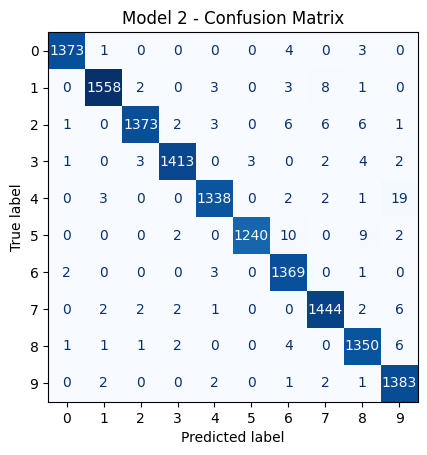

In [ ]:
test_loss2, test_accuracy2 = model2.evaluate(X_test, y_test, verbose=0)

print(f"Model 1 test accuracy: {test_accuracy:.4f}  |  test loss: {test_loss:.4f}")
print(f"Model 2 test accuracy: {test_accuracy2:.4f}  |  test loss: {test_loss2:.4f}")

y_pred_proba2 = model2.predict(X_test, verbose=0)
y_pred2 = np.argmax(y_pred_proba2, axis=1)

cm2 = confusion_matrix(y_test, y_pred2)
disp2 = ConfusionMatrixDisplay(cm2)
disp2.plot(cmap="Blues", colorbar=False)
plt.title("Model 2 - Confusion Matrix")
plt.savefig("confusion_matrix_model2.png", dpi=150, bbox_inches="tight")
plt.show()

**Top 5 errors of model 2**

In [ ]:
errors2 = cm2.copy()
np.fill_diagonal(errors2, 0)
top2 = np.argsort(errors2, axis=None)[::-1][:5]
print("Top 5 errors, model 2:")
for idx in top2:
    t, p = np.unravel_index(idx, errors2.shape)
    print(f"  True {t} → predicted {p}: {errors2[t, p]} images")

Top 5 errors, model 2:
  True 4 → predicted 9: 19 images
  True 5 → predicted 6: 10 images
  True 5 → predicted 8: 9 images
  True 1 → predicted 7: 8 images
  True 7 → predicted 9: 6 images


**Direct comparison of the confusion pairs from Part C**

In [ ]:
print("\nComparison of the confusion pairs:")
for t, p in [(9, 4), (4, 9), (9, 7), (7, 9)]:
    print(f"  True {t} → pred {p}:  model 1 = {cm1[t, p]:2d},  model 2 = {cm2[t, p]:2d}")

errors_m1 = cm1.sum() - np.trace(cm1)
errors_m2 = cm2.sum() - np.trace(cm2)
print(f"\nTotal errors:  model 1 = {errors_m1},  model 2 = {errors_m2}")


Comparison of the confusion pairs:
  True 9 → pred 4:  model 1 =  7,  model 2 =  2
  True 4 → pred 9:  model 1 = 11,  model 2 = 19
  True 9 → pred 7:  model 1 =  5,  model 2 =  2
  True 7 → pred 9:  model 1 =  4,  model 2 =  6

Total errors:  model 1 = 174,  model 2 = 159


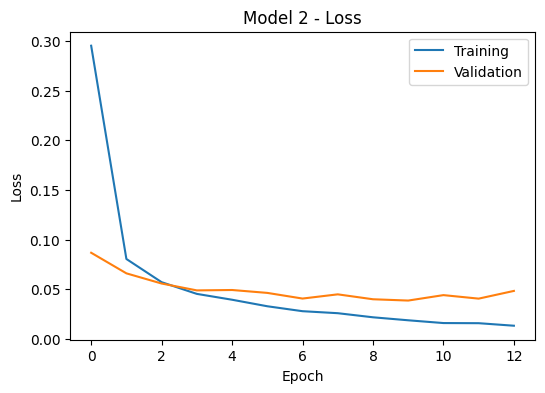

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(history2.history["loss"], label="Training")
plt.plot(history2.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model 2 - Loss")
plt.legend()
plt.savefig("learning_curves_model2.png", dpi=150, bbox_inches="tight")
plt.show()

### Ethical considerations

A digit reader does not perform equally well for everyone. Handwriting varies by age, country, and schooling, and a model trained mostly on one style may read another less reliably.
**Write two or three sentences here** on the risks of putting this model into a real reading pipeline. Consider whose handwriting might be under-represented in the training data, and what the consequence of a confident but wrong reading would be in the setting above.

MNIST was collected from American Census Bureau employees and high-school students, so the model has mostly seen one regional style of handwriting. Writers from other countries may be read less reliably: for example, many Europeans write a 1 with a long upstroke and cross their 7s, which could make the 1 → 7 confusion (already 8 errors in model 2) much more frequent. Children, elderly people, or people with motor impairments may also write in ways the training data under-represents. The biggest risk in a real pipeline is a confident misreading: the softmax output always picks a digit, often with a high probability, even when it is wrong, so a misread postcode silently sends a letter to the wrong city and a misread account number can send money to the wrong person. A safer system would send low-confidence readings to a human for review, rather than accepting every prediction automatically.


## Wrapping up

Bring your findings together. **Write a short paragraph** that answers the central question directly:

- Where did your first model make most of its mistakes?
- Did your prediction in Part D turn out to be correct?
- For each of the two confusion pairs you identified, what was the count before and after the change?
- Did your one change move the mistakes, and is the difference large enough to be meaningful?

**What to hand in:** this completed notebook, with both confusion matrices visible in the output, and your written answers in the three markdown cells above (Part C, Part D, and this one).

The first model reached 98.8% test accuracy and made 174 errors, most of them concentrated on a few visually similar digits: the pair 4 ↔ 9 accounted for 18 errors (4 → 9: 11, 9 → 4: 7) and the pair 7 ↔ 9 for 9 errors (9 → 7: 5, 7 → 9: 4). My prediction for the deeper network was only partly correct. Test accuracy rose slightly to 98.9% (159 errors), and the 7 ↔ 9 pair barely changed, from 9 to 8 errors (9 → 7: 5 → 2, 7 → 9: 4 → 6). However, the 4 ↔ 9 confusion did not decrease; it rose from 18 to 21, because 9 → 4 fell from 7 to 2 while 4 → 9 rose from 11 to 19. So the change moved the mistakes rather than removing them: the first model was more balanced between the two directions, while the deeper model consistently answers "9" for ambiguous images, and new errors appeared, such as 5 → 6, 5 → 8 and 1 → 7. I ran the whole notebook twice, and while the exact counts changed between runs, this shift towards "9" appeared both times, so it seems to be a real effect of the change. The overall improvement of 15 errors (0.1 percentage points), on the other hand, is too small to be considered meaningful, since the counts already varied by a similar amount between my two runs with the same seed. The deeper model also learned faster but started to overfit more clearly, and early stopping restored its best weights from its best epoch.